# One dataset, many estimators

Every topic of the course is a different answer to the same question: *what would happen to these patients under
surgery vs the drug?* This notebook takes **one** simulated hospital (the course's running example, with nonlinear
confounding by severity and age plus three irrelevant covariates) and runs every estimator from topics 01–08 on it, so
the differences are about the methods, not the data.

| § | What |
|---|---|
| 1 | The data and the truth |
| 2 | Regression's hidden weights (FWL), made visible |
| 3 | Every ATE estimator on one dataset |
| 4 | The same, over 40 datasets: bias, RMSE, CI coverage |
| 5 | CATE: who benefits? Meta-learners, orthogonal learners, causal tree |
| 6 | Linear vs nonlinear world: when is flexibility needed? |

Modules: [`hospital.py`](../src/hospital.py) (simulator), [`estimators.py`](../src/estimators.py) (all ATE and CATE
estimators), [`learners.py`](../src/learners.py) (NumPy nuisance models), [`tree.py`](../src/tree.py) (causal tree).

In [1]:
import sys, time
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

from src.hospital import make_hospital, severity_bucket
from src import estimators as E
from src.learners import Logistic
from src.tree import CausalTree

plt.rcParams["figure.dpi"] = 100
N = 2000
d = make_hospital(N, seed=0, n_noise=3, nonlinear=True)
X, T, Y = d.X, d.T, d.Y
print(f"{N} patients, covariates {d.names}, {T.mean():.0%} operated on")
print(f"true ATE {d.ate:+.3f}   ATT {d.att:+.3f}   ATC {d.atc:+.3f}")

2000 patients, covariates ('severity', 'age', 'noise0', 'noise1', 'noise2'), 46% operated on
true ATE +0.100   ATT +0.183   ATC +0.028


## 1. The data and the truth

The structural equations are in [`hospital.py`](../src/hospital.py). Propensity, baseline and effect are all nonlinear;
the effect depends on severity and, for severe patients, on age. Overlap is decent but not perfect.

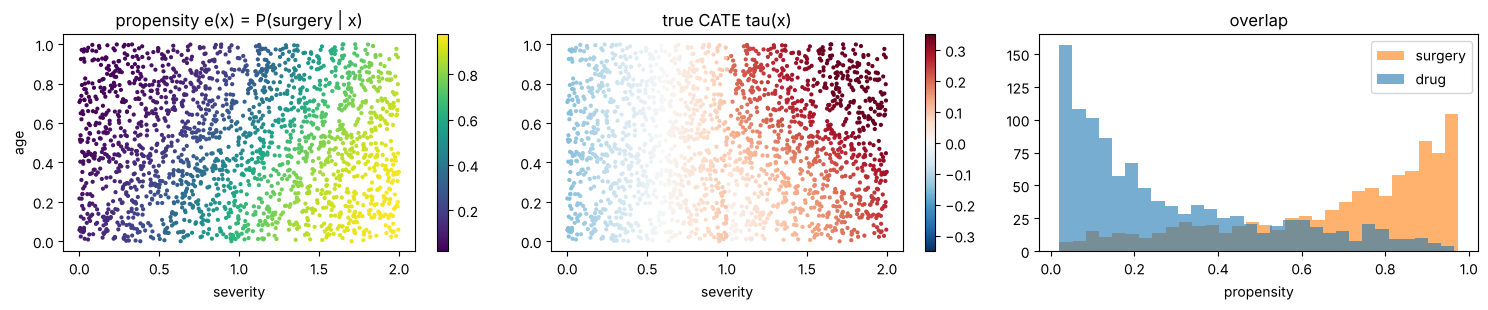

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
sc = ax[0].scatter(d.S, d.X[:, 1], c=d.e, cmap="viridis", s=4); plt.colorbar(sc, ax=ax[0])
ax[0].set_xlabel("severity"); ax[0].set_ylabel("age"); ax[0].set_title("propensity e(x) = P(surgery | x)")
sc = ax[1].scatter(d.S, d.X[:, 1], c=d.tau, cmap="RdBu_r", vmin=-0.35, vmax=0.35, s=4); plt.colorbar(sc, ax=ax[1])
ax[1].set_xlabel("severity"); ax[1].set_title("true CATE tau(x)")
ax[2].hist(d.e[T == 1], 30, alpha=0.6, label="surgery", color="tab:orange"); ax[2].hist(d.e[T == 0], 30, alpha=0.6, label="drug", color="tab:blue")
ax[2].set_xlabel("propensity"); ax[2].legend(); ax[2].set_title("overlap")
plt.tight_layout(); plt.show()

## 2. Regression's hidden weights

From the regression lecture: by Frisch–Waugh–Lovell, the coefficient of $T$ in $Y \sim T + X$ is
$\text{Cov}(Y, \tilde T) / \text{Var}(\tilde T)$ with $\tilde T$ the residual of $T$ on $X$. With a categorical $X$ this is
a weighted average of the per-stratum effects with weights $\propto P(x)\,\text{Var}(T \mid x)$, not $P(x)$. Below, $X$
is 10 severity strata (as dummies): the regression's implicit weights, the ATE's weights, and the two answers.

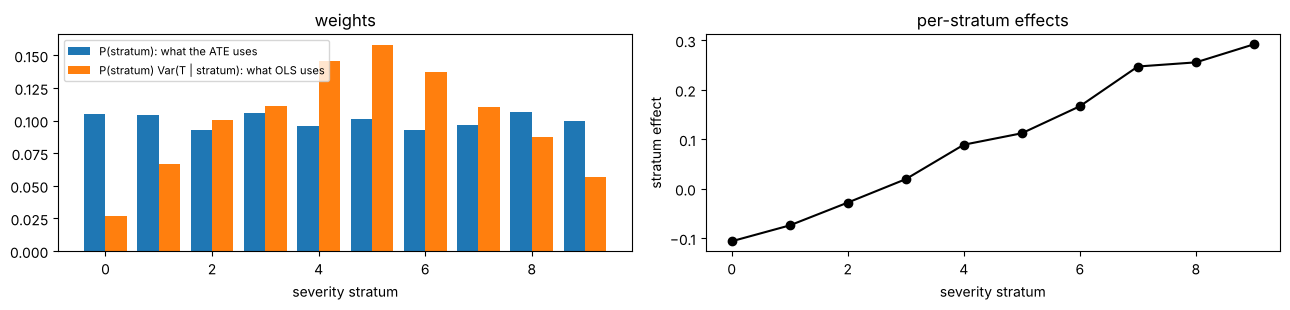

OLS coefficient             +0.1112
FWL (two-step)              +0.1112
variance-weighted average   +0.1112
P(x)-weighted average (ATE) +0.0961   true ATE +0.0996


In [3]:
k = 10
strata = np.minimum((d.S / 2 * k).astype(int), k - 1)
dummies = np.eye(k)[strata][:, 1:]
beta_ols = E.regression_adjustment(dummies, T, Y).ate
beta_fwl, T_res = E.fwl(dummies, T, Y)
eff, pw, vw = [], [], []
for s in range(k):
    m = strata == s
    eff.append(Y[m & (T == 1)].mean() - Y[m & (T == 0)].mean())
    pw.append(m.mean()); vw.append(m.mean() * T[m].var())
eff, pw, vw = map(np.array, (eff, pw, vw)); vw /= vw.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
x = np.arange(k)
ax[0].bar(x - 0.2, pw, 0.4, label="P(stratum): what the ATE uses"); ax[0].bar(x + 0.2, vw, 0.4, label="P(stratum) Var(T | stratum): what OLS uses")
ax[0].set_xlabel("severity stratum"); ax[0].legend(fontsize=8); ax[0].set_title("weights")
ax[1].plot(x, eff, "ko-"); ax[1].set_xlabel("severity stratum"); ax[1].set_ylabel("stratum effect"); ax[1].set_title("per-stratum effects")
plt.tight_layout(); plt.show()
print(f"OLS coefficient             {beta_ols:+.4f}")
print(f"FWL (two-step)              {beta_fwl:+.4f}")
print(f"variance-weighted average   {np.sum(vw * eff):+.4f}")
print(f"P(x)-weighted average (ATE) {np.sum(pw * eff):+.4f}   true ATE {d.ate:+.4f}")

The three regression numbers agree to machine precision. OLS over-weights the middle strata (where treatment is most
uncertain) and under-weights the extremes, where the effect is most negative and most positive. The interacted
regression / g-computation and every propensity method below fix the weighting.

## 3. Every ATE estimator on one dataset

In [4]:
def run_all(d, seed=0):
    X, T, Y = d.X, d.T, d.Y
    out = {}
    t0 = time.perf_counter()
    nu = E.cross_fit_nuisances(X, T, Y, seed=seed)
    t_nu = time.perf_counter() - t0
    e_lin = np.clip(Logistic().fit(X, T).predict(X), 0.01, 0.99)
    strata = np.minimum((d.S / 2 * 10).astype(int), 9)
    jobs = [
        ("naive difference", "01", lambda: E.naive_difference(X, T, Y)),
        ("stratified, 10 severity bins", "01", lambda: E.stratified(strata, T, Y)),
        ("1-NN matching on X", "01", lambda: E.matching(X, T, Y)),
        ("OLS  Y ~ T + X", "02", lambda: E.regression_adjustment(X, T, Y)),
        ("interacted OLS (g-computation)", "02", lambda: E.g_computation(X, T, Y)),
        ("IPW, logistic propensity", "03", lambda: E.ipw(X, T, Y, e=e_lin)),
        ("IPW (Hajek), flexible propensity", "03", lambda: E.ipw(X, T, Y, e=nu["e"], normalized=True)),
        ("AIPW / DML (cross-fitted)", "03/08", lambda: E.aipw(X, T, Y, nuis=nu)),
        ("S-learner", "05", lambda: E.s_learner(X, T, Y)),
        ("T-learner", "05", lambda: E.t_learner(X, T, Y)),
        ("X-learner", "05", lambda: E.x_learner(X, T, Y)),
        ("DML partially linear", "08", lambda: E.dml_plr(X, T, Y, nuis=nu)),
        ("R-learner", "08", lambda: E.r_learner(X, T, Y, nuis=nu)),
        ("causal tree (honest, IPW leaves)", "04",
         lambda: (lambda t: E.Estimate(float(t.predict(X).mean()), cate=t.predict))(
             CausalTree("honest", min_leaf=60, seed=seed).fit(X, T, Y, e=nu["e"]))),
    ]
    for name, topic, f in jobs:
        t0 = time.perf_counter(); est = f(); dt = time.perf_counter() - t0
        out[name] = dict(topic=topic, est=est, sec=dt + (t_nu if "nu" in f.__code__.co_freevars else 0))
    return out

res = run_all(d)
print(f"{'estimator':>34} {'topic':>6} | {'ATE':>7} {'error':>7} | {'95% CI':>17} | {'sec':>5}")
print("-" * 90)
for name, r in res.items():
    est = r["est"]; ci = est.ci()
    cis = f"{ci[0]:+.3f} .. {ci[1]:+.3f}" if ci else ""
    print(f"{name:>34} {r['topic']:>6} | {est.ate:+.3f} {est.ate - d.ate:+.3f} | {cis:>17} | {r['sec']:5.2f}")
print(f"{'truth':>34} {'':>6} | {d.ate:+.3f}")

                         estimator  topic |     ATE   error |            95% CI |   sec
------------------------------------------------------------------------------------------
                  naive difference     01 | +0.054 -0.046 |  +0.040 .. +0.067 |  0.00
      stratified, 10 severity bins     01 | +0.096 -0.004 |  +0.081 .. +0.111 |  0.00
                1-NN matching on X     01 | +0.087 -0.013 |  +0.077 .. +0.097 |  0.45
                    OLS  Y ~ T + X     02 | +0.134 +0.034 |  +0.117 .. +0.150 |  0.00
    interacted OLS (g-computation)     02 | +0.110 +0.011 |                   |  0.00
          IPW, logistic propensity     03 | +0.122 +0.022 |  +0.042 .. +0.201 |  0.00
  IPW (Hajek), flexible propensity     03 | +0.097 -0.003 |                   |  0.21
         AIPW / DML (cross-fitted)  03/08 | +0.101 +0.001 |  +0.083 .. +0.118 |  0.21
                         S-learner     05 | +0.109 +0.010 |                   |  0.03
                         T-learner     05 | +0.

## 4. Over 40 datasets

One dataset can flatter or embarrass any method. Repeat on 40 independent hospitals of 2000 patients.

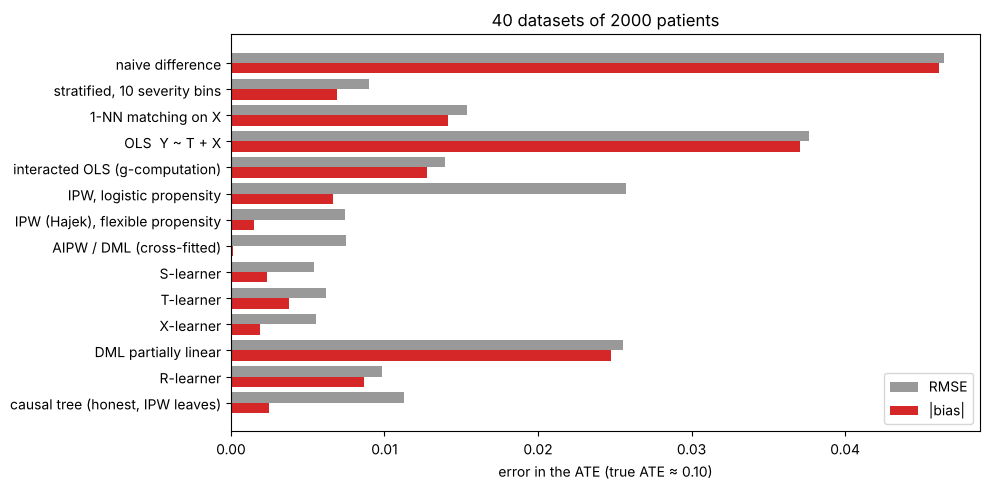

                         estimator |    bias   RMSE | CI coverage
                  naive difference | -0.0461 0.0465 |          0%
      stratified, 10 severity bins | -0.0069 0.0090 |         85%
                1-NN matching on X | -0.0141 0.0154 |         25%
                    OLS  Y ~ T + X | +0.0371 0.0377 |          0%
    interacted OLS (g-computation) | +0.0127 0.0139 |           -
          IPW, logistic propensity | -0.0067 0.0257 |        100%
  IPW (Hajek), flexible propensity | +0.0015 0.0075 |           -
         AIPW / DML (cross-fitted) | -0.0001 0.0075 |        100%
                         S-learner | +0.0023 0.0054 |           -
                         T-learner | -0.0038 0.0062 |           -
                         X-learner | +0.0019 0.0056 |           -
              DML partially linear | +0.0248 0.0256 |          8%
                         R-learner | +0.0087 0.0098 |           -
  causal tree (honest, IPW leaves) | -0.0025 0.0112 |           -


In [5]:
R = 40
errs, cover = {}, {}
for r in range(R):
    dd = make_hospital(N, seed=1000 + r, n_noise=3, nonlinear=True)
    for name, x in run_all(dd, seed=r).items():
        errs.setdefault(name, []).append(x["est"].ate - dd.ate)
        ci = x["est"].ci()
        if ci:
            cover.setdefault(name, []).append(ci[0] <= dd.ate <= ci[1])
names = list(errs)
bias = np.array([np.mean(errs[n]) for n in names]); rmse = np.array([np.sqrt(np.mean(np.square(errs[n]))) for n in names])
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(names))[::-1]
ax.barh(y + 0.2, rmse, 0.4, label="RMSE", color="0.6"); ax.barh(y - 0.2, np.abs(bias), 0.4, label="|bias|", color="tab:red")
ax.set_yticks(y, names); ax.set_xlabel("error in the ATE (true ATE ≈ 0.10)"); ax.legend(); ax.set_title(f"{R} datasets of {N} patients")
plt.tight_layout(); plt.show()
print(f"{'estimator':>34} | {'bias':>7} {'RMSE':>6} | {'CI coverage':>11}")
for n, b_, r_ in zip(names, bias, rmse):
    c = f"{np.mean(cover[n]):.0%}" if n in cover else "-"
    print(f"{n:>34} | {b_:+.4f} {r_:.4f} | {c:>11}")

Reading the table (numbers from this run):

* **Naive** is off by about half the effect: confounding.
* **Stratifying on severity** ignores age, which also confounds here, so a small bias remains, and its interval
  undercovers. **Matching** on all five covariates pays for the three noise dimensions (nearest neighbours degrade
  with dimension), and its naive standard error ignores the matching bias, so the interval is far too optimistic.
* **OLS** is biased twice over: a linear model of a nonlinear baseline, and variance weighting (§2). The **interacted
  OLS** fixes the weighting but not the misspecification.
* **IPW with a linear logistic propensity** is noisy and its Horvitz-Thompson interval is conservative; with a
  flexible propensity (and Hajek normalization) it does much better.
* **AIPW/DML** and the flexible **meta-learners** are close to unbiased. AIPW is the only one of them that comes with a
  standard error justified by theory (orthogonality + cross-fitting).
* **DML partially linear** converges to the overlap-weighted effect, not the ATE (see
  [08](../../08-orthogonal-learning/)), hence its "bias".

## 5. CATE: who benefits?

The ATE hides that surgery hurts mild patients and helps severe ones. Each CATE method below is scored on 20,000 new
patients by the RMSE of $\hat\tau(x)$ against the truth (often called PEHE).

In [6]:
test = make_hospital(20000, seed=999, n_noise=3, nonlinear=True)
cate_methods = ["interacted OLS (g-computation)", "S-learner", "T-learner", "X-learner", "R-learner", "causal tree (honest, IPW leaves)"]
pehe = {m: [] for m in cate_methods + ["DR-learner"]}
for r in range(10):
    dd = make_hospital(N, seed=2000 + r, n_noise=3, nonlinear=True)
    out = run_all(dd, seed=r)
    for m in cate_methods:
        pehe[m].append(np.sqrt(np.mean((out[m]["est"].cate(test.X) - test.tau) ** 2)))
    pehe["DR-learner"].append(np.sqrt(np.mean((E.dr_learner(dd.X, dd.T, dd.Y).cate(test.X) - test.tau) ** 2)))
print(f"{'method':>34} | RMSE of tau_hat(x) over 10 datasets")
for m, v in pehe.items():
    print(f"{m:>34} | {np.mean(v):.3f} ± {np.std(v):.3f}")
print(f"{'(constant = true ATE)':>34} | {test.tau.std():.3f}")

                            method | RMSE of tau_hat(x) over 10 datasets
    interacted OLS (g-computation) | 0.083 ± 0.005
                         S-learner | 0.052 ± 0.002
                         T-learner | 0.048 ± 0.005
                         X-learner | 0.039 ± 0.003
                         R-learner | 0.038 ± 0.005
  causal tree (honest, IPW leaves) | 0.060 ± 0.008
                        DR-learner | 0.051 ± 0.014
             (constant = true ATE) | 0.153


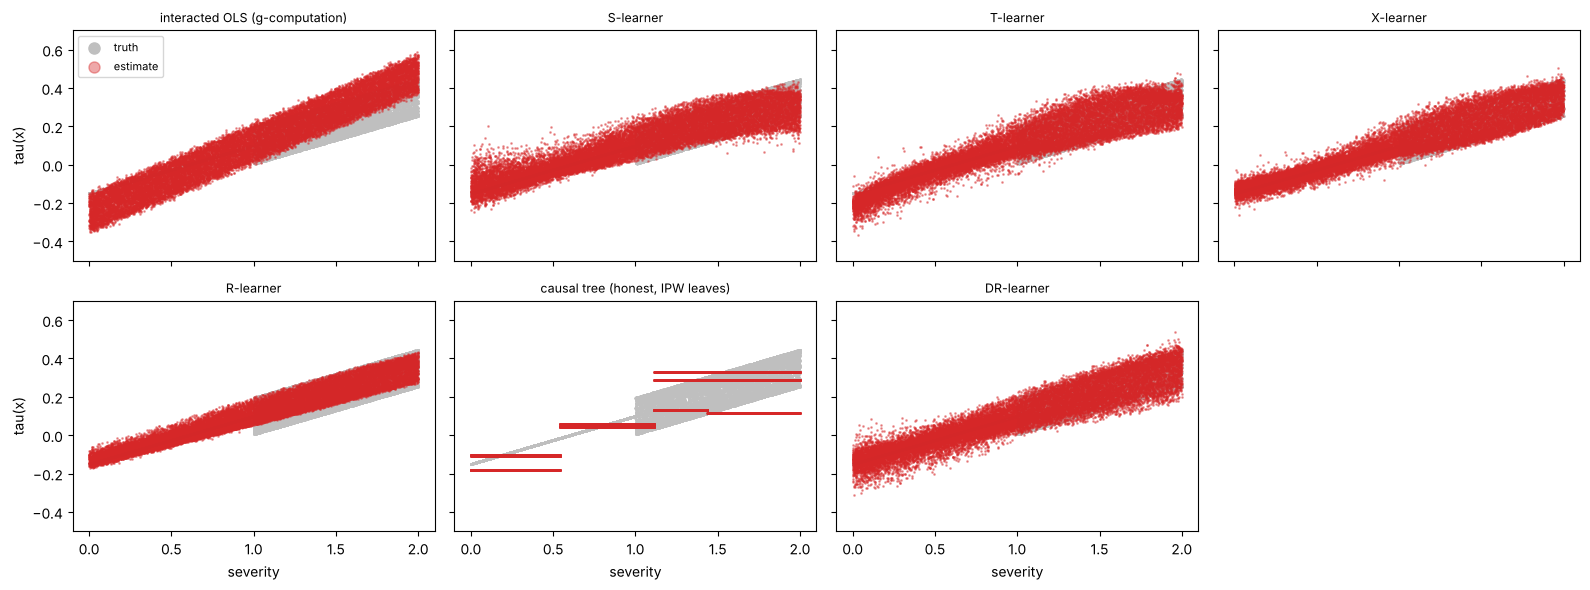

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey=True)
o = np.argsort(test.S)
show = cate_methods + ["DR-learner"]
for ax, m in zip(axes.flat, show):
    pred = E.dr_learner(X, T, Y).cate(test.X) if m == "DR-learner" else res[m]["est"].cate(test.X)
    ax.scatter(test.S[o], test.tau[o], s=1, color="0.75", label="truth")
    ax.scatter(test.S[o], pred[o], s=1, color="tab:red", alpha=0.4, label="estimate")
    ax.set_title(m, fontsize=9); ax.set_ylim(-0.5, 0.7)
axes.flat[-1].axis("off")
for ax in axes[1]: ax.set_xlabel("severity")
for ax in axes[:, 0]: ax.set_ylabel("tau(x)")
axes.flat[0].legend(markerscale=8, fontsize=8)
plt.tight_layout(); plt.show()

## 6. Linear vs nonlinear world

The same comparison on the *linear* hospital (only severity, linear propensity in severity, linear baseline and
effect). Which methods were only needed because of nonlinearity?

In [8]:
rows = {}
for world, nl, nn in [("linear", False, 0), ("nonlinear", True, 3)]:
    for r in range(20):
        dd = make_hospital(N, seed=3000 + r, n_noise=nn, nonlinear=nl)
        for name, x in run_all(dd, seed=r).items():
            rows.setdefault(name, {}).setdefault(world, []).append(x["est"].ate - dd.ate)
print(f"{'estimator':>34} | {'RMSE linear':>11} | {'RMSE nonlinear':>14}")
for n, v in rows.items():
    print(f"{n:>34} | {np.sqrt(np.mean(np.square(v['linear']))):>11.4f} | {np.sqrt(np.mean(np.square(v['nonlinear']))):>14.4f}")

                         estimator | RMSE linear | RMSE nonlinear
                  naive difference |      0.1578 |         0.0462
      stratified, 10 severity bins |      0.0058 |         0.0114
                1-NN matching on X |      0.0079 |         0.0157
                    OLS  Y ~ T + X |      0.0101 |         0.0378
    interacted OLS (g-computation) |      0.0068 |         0.0130
          IPW, logistic propensity |      0.0191 |         0.0216
  IPW (Hajek), flexible propensity |      0.0072 |         0.0092
         AIPW / DML (cross-fitted) |      0.0068 |         0.0092
                         S-learner |      0.0061 |         0.0053
                         T-learner |      0.0060 |         0.0088
                         X-learner |      0.0062 |         0.0058
              DML partially linear |      0.0101 |         0.0250
                         R-learner |      0.0063 |         0.0088
  causal tree (honest, IPW leaves) |      0.0087 |         0.0121


In the linear world nearly everything works, including OLS (the variance weights happen to be symmetric around the
mean effect here). Nonlinearity and extra covariates are what separate the methods: they are why the course moves from
regression to propensity scores to ML nuisances with orthogonal scores.